<a href="https://colab.research.google.com/github/Artomic2020/Break_the_Universe/blob/main/Assignment3_IDATG2208.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Exercise-1: Training Deep Neural Network
on Fashion-MNIST


Train a controlled deep neural network on the Fashion-MNIST dataset
(tf.keras.datasets.fashion
mnist). Set random seeds to 42. Load Fashion-MNIST
and normalize pixel values to [0,1]. Build the network using the following configuration:
• Flatten input images to 28 × 28 = 784 features
• 3 hidden layers, 100 neurons each
• ELU activation function
• He normal initialization
• Output layer: 10 neurons with softmax
• Optimizer: Nadam
• learning rate = 0.001, loss=sparse
categorical
crossentropy
• EarlyStopping callback: monitor validation loss, patience = 5, restore best weights
• epochs = 50, batch size = 32
• Use only the first 2000 training samples and first 400 test samples

In [1]:
import tensorflow as tf

# Load the Fashion MNIST dataset
(train_images, train_labels), (test_images, test_labels) = tf.keras.datasets.fashion_mnist.load_data()

# Print dataset shapes
print(f'Training images: {train_images.shape}')
print(f'Test images: {test_images.shape}')

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Test images: (10000, 28, 28)


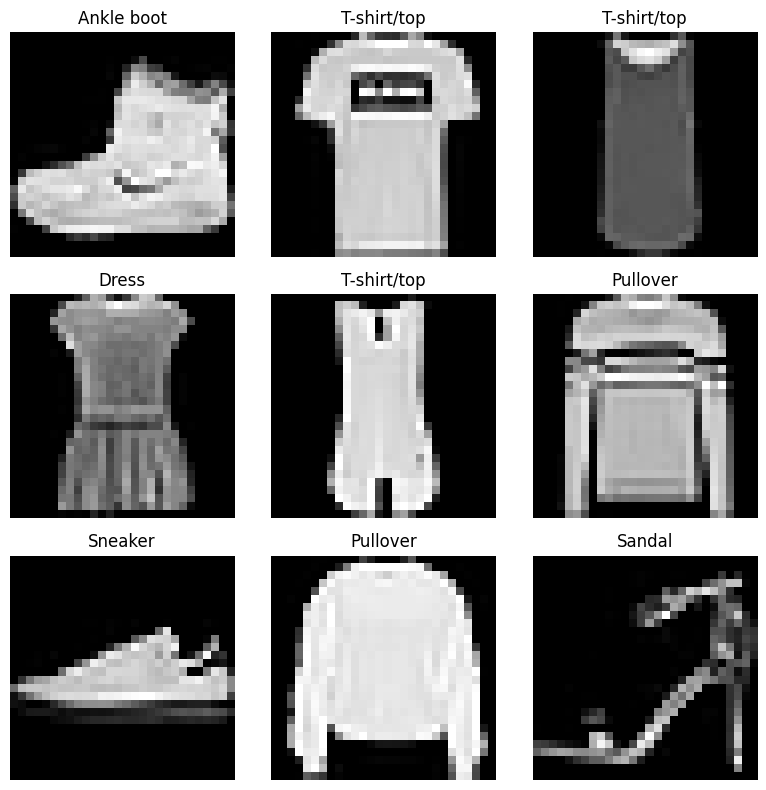

In [2]:
import matplotlib.pyplot as plt

# Define class names for Fashion MNIST
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Plot the first 9 training images
plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(train_images[i], cmap='gray')
    plt.title(class_names[train_labels[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()

In [3]:
train_images.shape

(60000, 28, 28)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Normalize pixel values to [0, 1]
train_images = train_images / 255.0
test_images = test_images / 255.0

In [5]:
len(train_labels)


60000

In [6]:
len(train_images)

60000

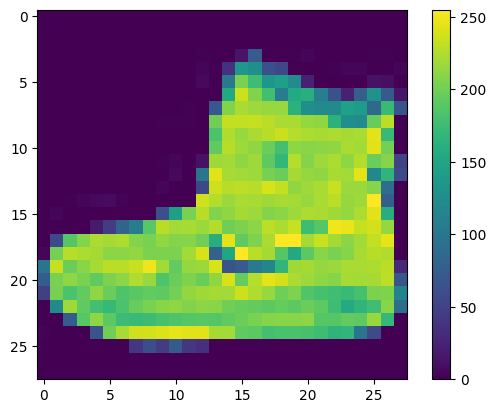

In [7]:
plt.figure()
plt.imshow(train_images[0])
plt.colorbar()
plt.grid(False)
plt.show()

In [8]:
train_images = train_images / 255.0  # Normalize by dividing by 255
test_images = test_images / 255.0

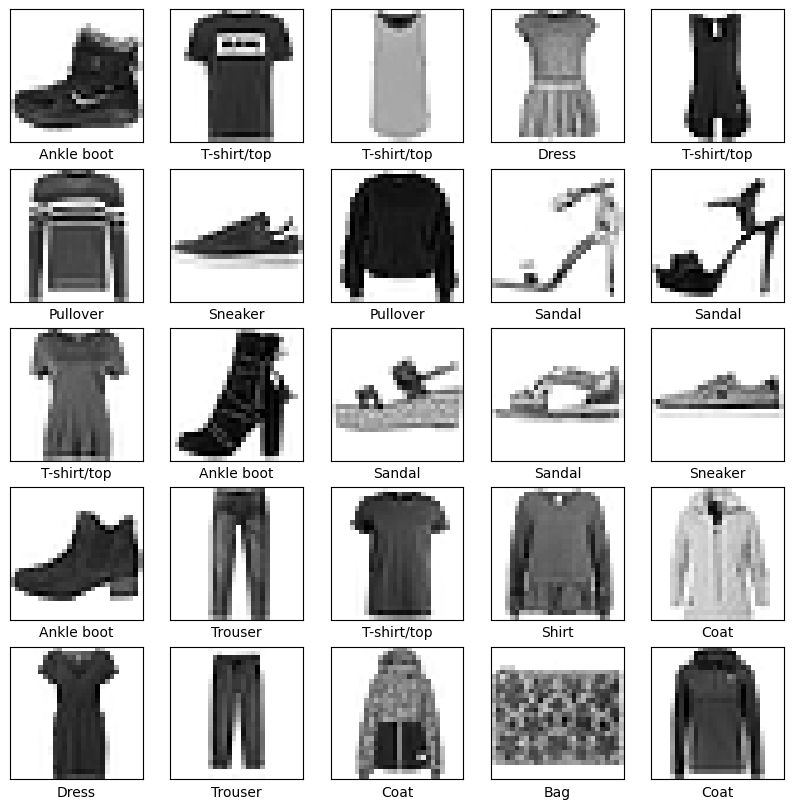

In [13]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[train_labels[i]])
plt.show()

In [14]:
model = tf.keras.Sequential([
    # Flatten input images to 28 x 28 = 784 features
    tf.keras.layers.Flatten(input_shape=(28, 28)),

    # 3 hidden layers, 100 neurons each, ELU activation, He normal initialization
    tf.keras.layers.Dense(100, activation='elu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(100, activation='elu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(100, activation='elu', kernel_initializer='he_normal'),

    # Output layer: 10 neurons with softmax
    tf.keras.layers.Dense(10, activation='softmax')
])

In [15]:
import numpy as np
import tensorflow as tf

# Set random seeds to 42
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

# Use only the first 2000 training samples and first 400 test samples
X_train_subset = train_images[:2000]
y_train_subset = train_labels[:2000]
X_test_subset = test_images[:400]
y_test_subset = test_labels[:400]

# Compile the model
optimizer = tf.keras.optimizers.Nadam(learning_rate=0.001)
model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# EarlyStopping callback: monitor validation loss, patience = 5, restore best weights
early_stopping_cb = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train the model with epochs = 50, batch size = 32
history = model.fit(
    X_train_subset, y_train_subset,
    epochs=50,
    batch_size=32,
    validation_data=(X_test_subset, y_test_subset),
    callbacks=[early_stopping_cb]
)

Epoch 1/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.6710 - loss: 0.9495 - val_accuracy: 0.7725 - val_loss: 0.6405
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8180 - loss: 0.5110 - val_accuracy: 0.7925 - val_loss: 0.6072
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8560 - loss: 0.4193 - val_accuracy: 0.7875 - val_loss: 0.5938
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8770 - loss: 0.3611 - val_accuracy: 0.7850 - val_loss: 0.5918
Epoch 5/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8960 - loss: 0.3176 - val_accuracy: 0.7925 - val_loss: 0.5957
Epoch 6/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9080 - loss: 0.2829 - val_accuracy: 0.8025 - val_loss: 0.5912
Epoch 7/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9175 - loss: 0.2513 - val_accuracy: 0.8175 - val_loss: 0.5789
Epoch 8/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9265 - loss: 0.2233 - val_accuracy: 0.8325 - val_los

**Q1.1 Report the obtained test accuracy**

In [17]:
test_loss, test_acc = model.evaluate(X_test_subset, y_test_subset)
print(f'Test accuracy: {test_acc:.4f}')

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8475 - loss: 0.5605 
Test accuracy: 0.8475


Based on the evaluation of your deep neural network on the first 400 test samples, the obtained test accuracy is 84.75% (or 0.8475), with a test loss of 0.5605.

Exercise-2: Training Deep Neural Network
on CIFAR-100 (Coarse Labels)

Train a controlled deep neural network on the CIFAR-100 dataset using its 20 coarse (superclass) labels, loaded with tf.keras.datasets.cifar100.load
data(label mode=’coarse’).
Set random seeds to 42. Load CIFAR-100 and normalize pixel values to [0,1]. Build the
network using the following configuration:
• Flatten input images to 32 × 32 × 3 = 3072 features
• 4 hidden layers, 256 neurons each
• ELU activation function
• He normal initialization
• Output layer: 20 neurons with softmax
• Optimizer: Nadam
• learning rate = 0.001, loss=sparse
categorical
crossentropy
• EarlyStopping callback: monitor validation loss, patience = 5, restore best weights
• epochs = 50, batch size = 128
• Use only the first 5000 training samples and first 1000 test samples
Q2.1 Report the obtained test accuracy.

In [ ]:
import tensorflow as tf

# Load the CIFAR-100 dataset using coarse (superclass) labels
(train_images_c100, train_labels_c100), (test_images_c100, test_labels_c100) = tf.keras.datasets.cifar100.load_data(label_mode='coarse')

# Print dataset shapes
print(f'CIFAR-100 Training images: {train_images_c100.shape}')
print(f'CIFAR-100 Test images: {test_images_c100.shape}')

 22888448/169001437 ━━━━━━━━━━━━━━━━━━━━ 40:36 17us/step